# Kuluri business model: 5-year projection, risk and grant scenarios

This notebook is the single source for every business number in the pitch deck
(`docs/pitch/kuluri_pitch_deck.pdf`) and the Q&A (`docs/qa/`). It writes the CSV
files in `docs/data/results/` and the charts in `docs/analysis/figures/`.

**Prices, as on the deck (slide 9).**

| Who | Price |
| --- | --- |
| Workers | Always €0 |
| Farmers | First season free, then **€25 per harvest season**, unlimited agreements |
| Co-ops | Year 1 free, then **€5 per member farm per year** |

They are **two separate products**, priced by who uses the data:

- **Farmers** pay the season pass for their own use: agreements, records, their own data.
- **Co-ops** pay €5 per member for **aggregated** data across their members (crews, harvest planning, reporting).

So a co-op member farm that uses Kuluri itself still has its own season pass. No advertising and no fee per agreement are counted. All figures are
**illustrative**: they show the logic of the model, not a forecast.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "analysis":          # run from docs/analysis
    ROOT = ROOT.parent.parent
OUT = ROOT / "docs" / "data" / "results"
FIG = ROOT / "docs" / "analysis" / "figures"
for d in [OUT / "model", OUT / "risk", OUT / "scenarios", FIG]:
    d.mkdir(parents=True, exist_ok=True)

YEARS = [1, 2, 3, 4, 5]
GREEN, ORANGE, CREAM, GREY, SAGE = "#173c2b", "#c65d3b", "#f5eedf", "#6e756d", "#6f8f6f"
plt.rcParams.update({"font.size": 13, "axes.facecolor": CREAM, "figure.facecolor": CREAM,
                     "axes.edgecolor": GREY, "axes.spines.top": False, "axes.spines.right": False})

## 1. Assumptions

Every input lives in one dictionary so the scenarios below only change what they name.

| Input | Value | Why |
| --- | --- | --- |
| Cretan olive-growing families | 95,000 | TU Crete, *Characteristics of oliviculture in Crete* |
| Share that hire outside labour | 30% → 28,500 farms | Team estimate; harvest needs extra hands on most holdings above family size |
| Adoption of those farms, Y1–Y5 | 1.1%, 4.2%, 14%, 23%, 32% | Rogers diffusion curve: innovators + early adopters ≈ 16% by Y3 |
| Farms that stay and pay after their free season | 70% | Retention assumption; tested from 50% to 85% in the risk section |
| Co-ops on the plan (joined), Y1–Y5 | 0, 2, 10, 25, 40 | Pilot co-op first, then cooperative networks in Heraklion and Lasithi |
| Members per co-op (Crete) | 315 | Average of Cretan olive-oil co-ops, range 21–1,350 (Kotsios & Pappa 2022, *Agricultural Economics Review* 23(1)); 315 × €5 = €1,575 per co-op per year |
| Olive-oil co-ops in Crete | about 83 | Same study: Heraklion 37, Lasithi 33, Chania 9, Rethymno 4. 25 paying co-ops in Y5 ≈ 30% of them |
| Members per co-op (Greece, grant scenario) | 183 | ~200,000 members (Sustainability 2024, 16(16):7202) ÷ 1,094 co-ops (COOPinCAP / national registry, 2025) |
| Grants | €20k in Y1 and €20k in Y2 | ESF+ / EIT Food-size launch grants |
| Fixed costs, Y1–Y5 | €6.5k, 30k, 52k, 63k, 72k | Bottom-up: company, legal, tech; part-time developer and community manager from Y2; co-op features from Y3 |
| Payment fees | 3% of subscription revenue | Card / SEPA processing |

In [2]:
BASE = dict(
    olive_families=95_000,
    hire_share=0.30,
    adoption=[0.011, 0.042, 0.14, 0.23, 0.32],
    retention=0.70,
    farm_price=25.0,           # € per farm per harvest season
    coop_member_price=5.0,     # € per member farm per year
    coop_size=315,             # members per Cretan olive-oil co-op (Kotsios & Pappa 2022)
    coops_joined=[0, 2, 10, 25, 40],
    grants=[20_000, 20_000, 0, 0, 0],
    fixed_costs=[6_500, 30_000, 52_000, 63_000, 72_000],
    payment_fee=0.03,
    extra_farms=[0, 0, 0, 0, 0],   # used by the grant scenario (rest of Greece)
)

## 2. The model

In [3]:
def run(p=BASE, **override):
    p = {**p, **override}
    hiring = p["olive_families"] * p["hire_share"]
    farms = np.array([hiring * a + e for a, e in zip(p["adoption"], p["extra_farms"])])
    # A farm pays from its second season on, if it stays.
    paying = np.array([0.0] + [farms[i - 1] * p["retention"] for i in range(1, 5)])
    joined = np.array(p["coops_joined"], dtype=float)
    coops_paying = np.concatenate([[0.0], joined[:-1]])        # Year 1 on the plan is free
    # Two products: each paying farm buys its season pass; each co-op buys aggregated data per member.
    rev_farms = paying * p["farm_price"]
    rev_coops = coops_paying * p["coop_size"] * p["coop_member_price"]
    subs = rev_farms + rev_coops
    grants = np.array(p["grants"], dtype=float)
    revenue = subs + grants
    costs = np.array(p["fixed_costs"], dtype=float) + p["payment_fee"] * subs
    net = revenue - costs
    return pd.DataFrame({
        "year": YEARS,
        "active_farms": farms.round(),
        "paying_farms": paying.round(),
        "coops_paying": coops_paying,
        "coop_members_covered": coops_paying * p["coop_size"],
        "revenue_season_pass_eur": rev_farms.round(),
        "revenue_coops_eur": rev_coops.round(),
        "revenue_grants_eur": grants,
        "revenue_total_eur": revenue.round(),
        "costs_eur": costs.round(),
        "net_profit_eur": net.round(),
        "net_profit_without_grants_eur": (net - grants).round(),
        "cumulative_profit_eur": net.cumsum().round(),
    })

base = run()
base

,year,active_farms,paying_farms,coops_paying,coop_members_covered,revenue_season_pass_eur,revenue_coops_eur,revenue_grants_eur,revenue_total_eur,costs_eur,net_profit_eur,net_profit_without_grants_eur,cumulative_profit_eur
0,1,314.0,0.0,0.0,0.0,0.0,0.0,20000.0,20000.0,6500.0,13500.0,-6500.0,13500.0
1,2,1197.0,219.0,0.0,0.0,5486.0,0.0,20000.0,25486.0,30165.0,-4678.0,-24678.0,8822.0
2,3,3990.0,838.0,2.0,630.0,20948.0,3150.0,0.0,24098.0,52723.0,-28625.0,-28625.0,-19804.0
3,4,6555.0,2793.0,10.0,3150.0,69825.0,15750.0,0.0,85575.0,65567.0,20008.0,20008.0,204.0
4,5,9120.0,4588.0,25.0,7875.0,114712.0,39375.0,0.0,154088.0,76623.0,77465.0,77465.0,77669.0


In [4]:
def headline(df):
    y5 = df.iloc[-1]
    no_grant = df["net_profit_without_grants_eur"]
    first_profit = next((int(r.year) for r in df.itertuples() if r.year > 2 and r.net_profit_without_grants_eur > 0), None)
    return {
        "year_profitable_without_grants": first_profit,
        "paying_farms_y5": int(y5.paying_farms),
        "revenue_y5_eur": int(y5.revenue_total_eur),
        "profit_y5_eur": int(y5.net_profit_eur),
        "cumulative_profit_y5_eur": int(y5.cumulative_profit_eur),
        "lowest_cumulative_eur": int(df.cumulative_profit_eur.min()),
        "year_of_lowest_cumulative": int(df.loc[df.cumulative_profit_eur.idxmin(), "year"]),
    }

H = headline(base)
H

{'year_profitable_without_grants': 4,
 'paying_farms_y5': 4588,
 'revenue_y5_eur': 154088,
 'profit_y5_eur': 77465,
 'cumulative_profit_y5_eur': 77669,
 'lowest_cumulative_eur': -19804,
 'year_of_lowest_cumulative': 3}

In [5]:
base.to_csv(OUT / "model" / "base_case_5_years.csv", index=False)
pd.DataFrame([H]).to_csv(OUT / "model" / "headline_numbers.csv", index=False)

unit = pd.DataFrame([
    {"item": "Season pass per farm", "eur": BASE["farm_price"]},
    {"item": "Co-op price per member farm", "eur": BASE["coop_member_price"]},
    {"item": "Average Cretan co-op (315 members), per year", "eur": BASE["coop_member_price"] * BASE["coop_size"]},
    {"item": "Year-1 costs (founders unpaid)", "eur": BASE["fixed_costs"][0]},
    {"item": "Season passes needed to cover Year-5 costs", "eur": round(BASE["fixed_costs"][4] / BASE["farm_price"])},
])
unit.to_csv(OUT / "model" / "unit_economics.csv", index=False)
unit

,item,eur
0,Season pass per farm,25.0
1,Co-op price per member farm,5.0
2,"Average Cretan co-op (315 members), per year",1575.0
3,Year-1 costs (founders unpaid),6500.0
4,Season passes needed to cover Year-5 costs,2880.0


## 3. Price sensitivity: what the farmer price does to the business

In [6]:
rows = []
for price in [10, 15, 17, 20, 25, 30, 35]:
    h = headline(run(farm_price=price))
    rows.append({"farm_price_eur_per_season": price, **h})
price_table = pd.DataFrame(rows)
price_table.to_csv(OUT / "model" / "price_sensitivity.csv", index=False)
price_table[["farm_price_eur_per_season", "year_profitable_without_grants", "profit_y5_eur", "cumulative_profit_y5_eur"]]

,farm_price_eur_per_season,year_profitable_without_grants,profit_y5_eur,cumulative_profit_y5_eur
0,10,5,10702,-45116
1,15,5,32956,-4188
2,17,5,41858,12183
3,20,4,55211,36740
4,25,4,77465,77669
5,30,4,99719,118597
6,35,4,121973,159526


## 4. Risk: First Chicago method (three weighted cases)

| Case | Weight | Adoption | Retention | Co-ops | Costs |
| --- | --- | --- | --- | --- | --- |
| Bear | 30% | ×0.5 | 55% | ×0.3 | ×1.15 |
| Base | 50% | ×1.0 | 70% | ×1.0 | ×1.0 |
| Bull | 20% | ×1.4 | 80% | ×1.3 | ×1.0 |

In [7]:
def scaled(adopt=1.0, retention=0.70, coop=1.0, cost=1.0, grants=None):
    return run(
        adoption=[min(a * adopt, 1.0) for a in BASE["adoption"]],
        retention=retention,
        coops_joined=[c * coop for c in BASE["coops_joined"]],
        fixed_costs=[c * cost for c in BASE["fixed_costs"]],
        grants=BASE["grants"] if grants is None else grants,
    )

cases = {
    "Bear": (0.30, dict(adopt=0.5, retention=0.55, coop=0.3, cost=1.15)),
    "Base": (0.50, dict()),
    "Bull": (0.20, dict(adopt=1.4, retention=0.80, coop=1.3, cost=1.0)),
}
fc_rows, curves = [], {}
for name, (w, kw) in cases.items():
    df = scaled(**kw)
    curves[name] = df.cumulative_profit_eur.values
    fc_rows.append({"case": name, "weight": w, **headline(df)})
first_chicago = pd.DataFrame(fc_rows)
expected = (first_chicago.weight * first_chicago.cumulative_profit_y5_eur).sum()
first_chicago.to_csv(OUT / "risk" / "first_chicago_cases.csv", index=False)
pd.DataFrame({"year": YEARS, **{k: v.round() for k, v in curves.items()}}).to_csv(
    OUT / "risk" / "cumulative_profit_by_case.csv", index=False)
print(f"Expected cumulative profit by Year 5: €{expected:,.0f}")
first_chicago

Expected cumulative profit by Year 5: €46,415


,case,weight,year_profitable_without_grants,paying_farms_y5,revenue_y5_eur,profit_y5_eur,cumulative_profit_y5_eur,lowest_cumulative_eur,year_of_lowest_cumulative
0,Bear,0.3,NaN,1803,56878,-27628,-119672,-119672,5
1,Base,0.5,4.0,4588,154088,77465,77669,-19804,3
2,Bull,0.2,4.0,7342,234728,155686,217412,-3503,3


## 5. Risk: Monte Carlo (10,000 runs)

Each run draws adoption, retention, co-op uptake and costs from triangular
distributions, and wins each €20k grant with 80% / 70% probability.

In [8]:
rng = np.random.default_rng(42)
N = 10_000
tri = lambda lo, mode, hi: rng.triangular(lo, mode, hi, N)
draws = pd.DataFrame({
    "adopt": tri(0.4, 1.0, 1.4), "retention": tri(0.5, 0.7, 0.85),
    "coop": tri(0.2, 1.0, 1.3), "cost": tri(0.9, 1.0, 1.3),
    "grant1": rng.random(N) < 0.8, "grant2": rng.random(N) < 0.7,
})
results = []
for r in draws.itertuples():
    df = scaled(r.adopt, r.retention, r.coop, r.cost,
                grants=[20_000 * r.grant1, 20_000 * r.grant2, 0, 0, 0])
    results.append((df.cumulative_profit_eur.iloc[-1], df.net_profit_eur.iloc[-1]))
mc = pd.DataFrame(results, columns=["cumulative_y5_eur", "profit_y5_eur"])
mc_summary = pd.DataFrame([{
    "runs": N,
    "p_profitable_in_year_5": (mc.profit_y5_eur > 0).mean(),
    "p_cumulative_positive_by_year_5": (mc.cumulative_y5_eur > 0).mean(),
    "p10_cumulative_eur": mc.cumulative_y5_eur.quantile(0.10).round(),
    "median_cumulative_eur": mc.cumulative_y5_eur.median().round(),
    "p90_cumulative_eur": mc.cumulative_y5_eur.quantile(0.90).round(),
    "mean_cumulative_eur": mc.cumulative_y5_eur.mean().round(),
}])
mc_summary.to_csv(OUT / "risk" / "monte_carlo_summary.csv", index=False)
mc.describe().round().to_csv(OUT / "risk" / "monte_carlo_distribution.csv")
mc_summary.T

,0
runs,10000.0000
p_profitable_in_year_5,0.9864
p_cumulative_positive_by_year_5,0.6759
p10_cumulative_eur,-43080.0000
median_cumulative_eur,25578.0000
p90_cumulative_eur,92223.0000
mean_cumulative_eur,24994.0000


In [9]:
npv = sum(n / 1.4 ** (i + 1) for i, n in enumerate(base.net_profit_eur))
npv_table = pd.DataFrame([{"discount_rate": 0.40, "npv_eur": round(npv),
                           "note": "40% = typical venture hurdle rate for early-stage start-ups"}])
npv_table.to_csv(OUT / "risk" / "npv.csv", index=False)
npv_table

,discount_rate,npv_eur,note
0,0.4,16436,40% = typical venture hurdle rate for early-st...


## 6. Scenario: a larger EU grant (if we win)

Same prices. A €500k ESF+-size grant arrives in Years 2 and 3 (€250k each, 20%
co-funded: half in kind, half by three founding co-ops). It pays for a full team,
faster adoption in Crete and a start in the rest of Greece from Year 3.

In [10]:
HIRING = BASE["olive_families"] * BASE["hire_share"]
grant_case = run(
    adoption=[0.011, 0.06, 0.18, 0.30, 0.42],
    coops_joined=[0, 8, 25, 60, 100],
    grants=[20_000, 250_000, 250_000, 0, 0],
    coop_size=183,   # Greek average: ~200,000 members / 1,094 co-ops
    fixed_costs=[6_500, 312_500 - 31_250, 312_500 - 31_250, 155_000, 170_000],
    extra_farms=[a * HIRING * 3 for a in [0, 0, 0.02, 0.06, 0.12]],
)
compare = pd.DataFrame({
    "year": YEARS,
    "current_plan_cumulative_eur": base.cumulative_profit_eur,
    "eu_grant_cumulative_eur": grant_case.cumulative_profit_eur,
    "current_plan_active_farms": base.active_farms,
    "eu_grant_active_farms": grant_case.active_farms,
})
grant_case.to_csv(OUT / "scenarios" / "eu_grant_5_years.csv", index=False)
compare.to_csv(OUT / "scenarios" / "current_plan_vs_eu_grant.csv", index=False)
compare

,year,current_plan_cumulative_eur,eu_grant_cumulative_eur,current_plan_active_farms,eu_grant_active_farms
0,1,13500.0,13500.0,314.0,314.0
1,2,8822.0,-12428.0,1197.0,1710.0
2,3,-19804.0,-7551.0,3990.0,6840.0
3,4,204.0,-24253.0,6555.0,13680.0
4,5,77669.0,91218.0,9120.0,22230.0


## 7. Charts (deck colours)

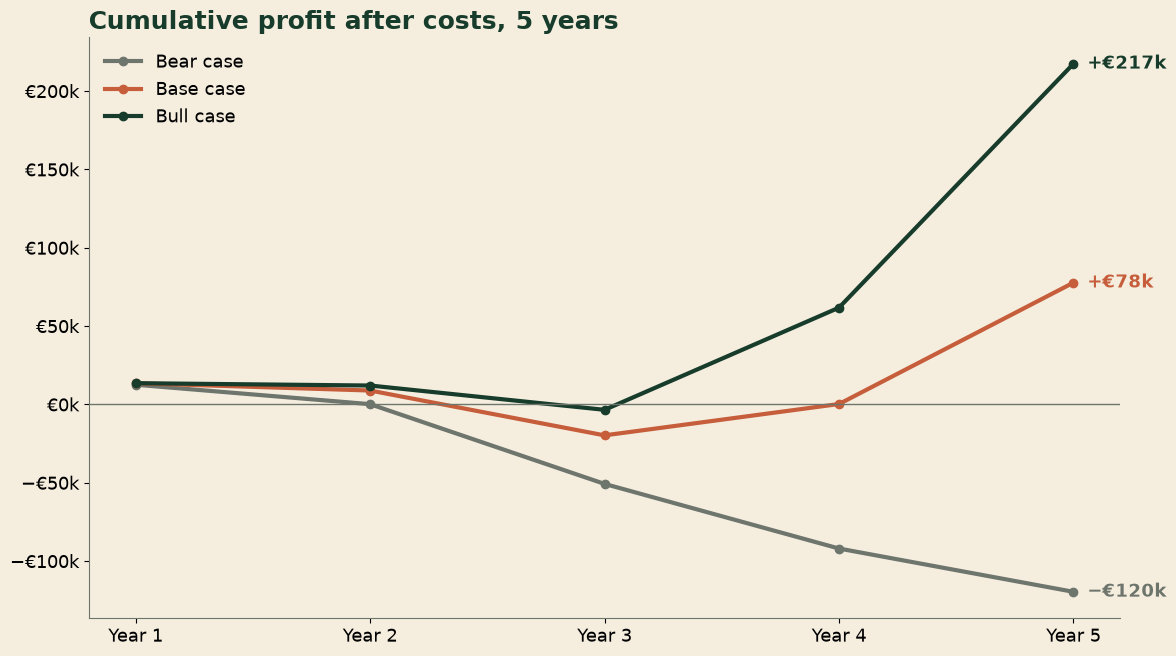

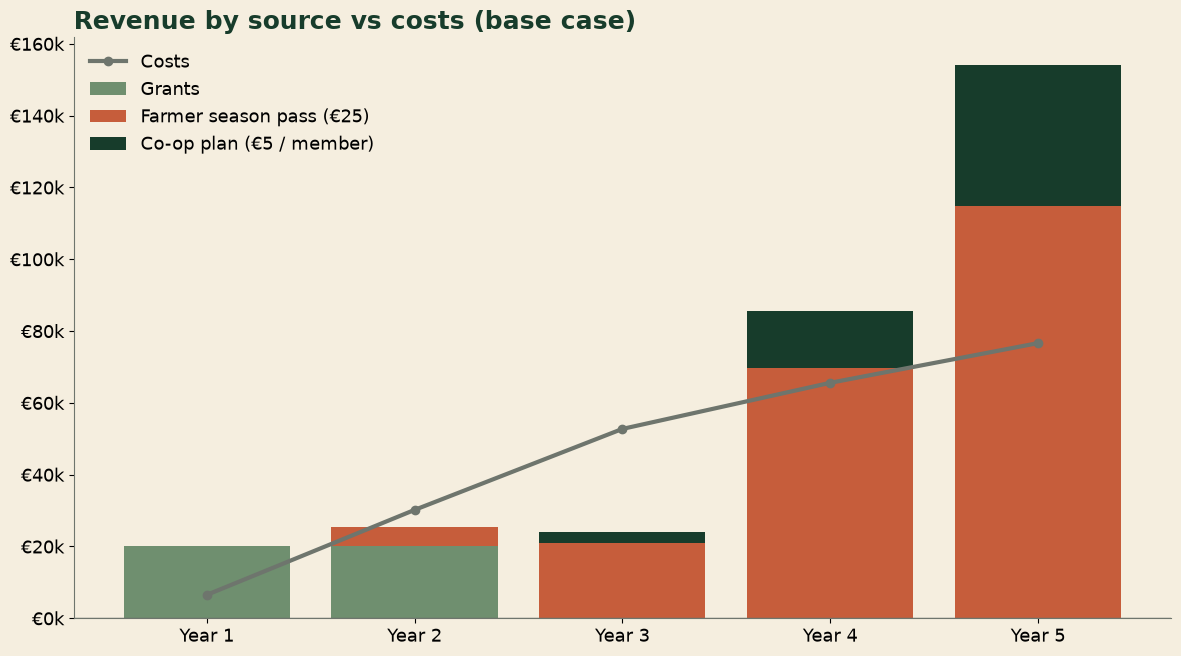

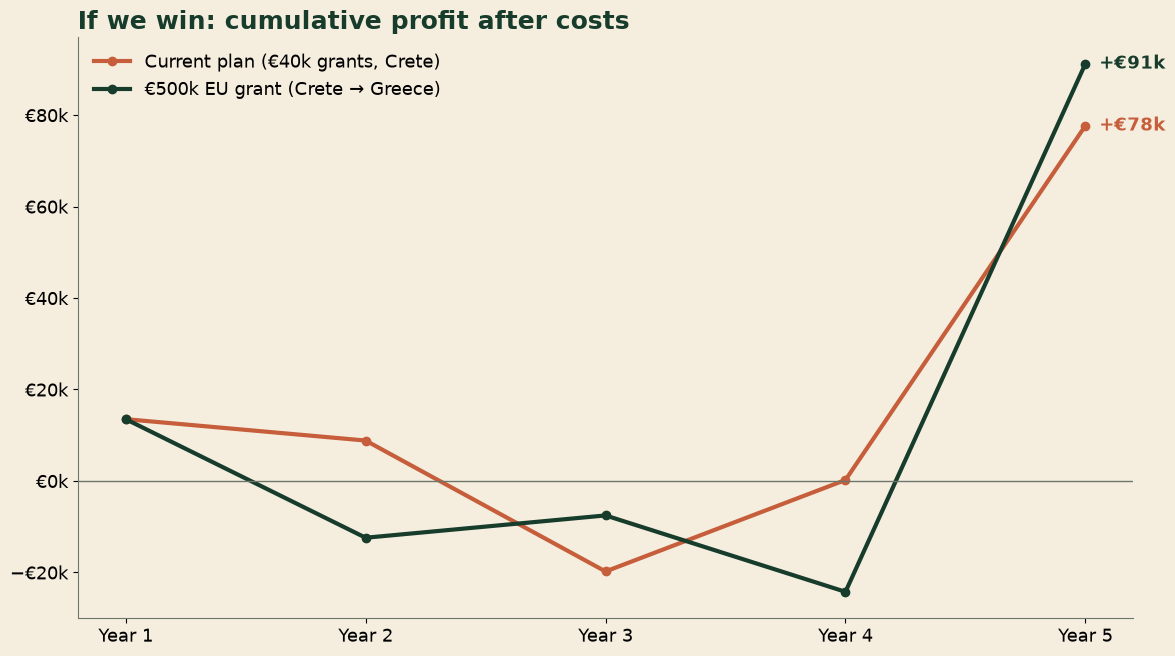

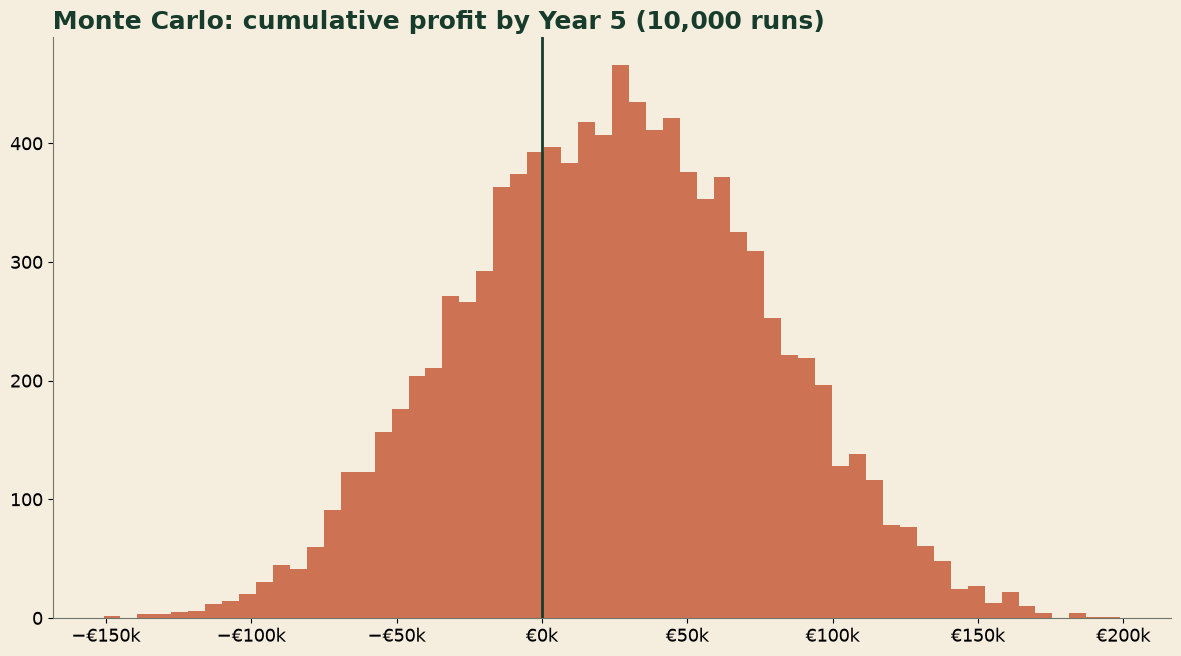

In [11]:
def k(v, sign=False):
    s = "+" if (sign and v > 0) else ("−" if v < 0 else "")
    return f"{s}€{abs(v)/1000:,.0f}k"

def euro_k(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: k(v)))
    ax.axhline(0, color=GREY, lw=1)
    ax.set_xticks(YEARS, [f"Year {y}" for y in YEARS])

fig, ax = plt.subplots(figsize=(12, 6.75))
for name, color in [("Bear", GREY), ("Base", ORANGE), ("Bull", GREEN)]:
    ax.plot(YEARS, curves[name], marker="o", lw=3, color=color, label=f"{name} case")
    ax.annotate(k(curves[name][-1], True), (5, curves[name][-1]),
                textcoords="offset points", xytext=(10, 0), va="center", color=color, fontweight="bold")
euro_k(ax)
ax.set_title("Cumulative profit after costs, 5 years", loc="left", color=GREEN, fontsize=18, fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "cumulative_profit_cases.png", dpi=160)

fig, ax = plt.subplots(figsize=(12, 6.75))
ax.bar(YEARS, base.revenue_grants_eur, color=SAGE, label="Grants")
ax.bar(YEARS, base.revenue_season_pass_eur, bottom=base.revenue_grants_eur, color=ORANGE, label="Farmer season pass (€25)")
ax.bar(YEARS, base.revenue_coops_eur, bottom=base.revenue_grants_eur + base.revenue_season_pass_eur,
       color=GREEN, label="Co-op plan (€5 / member)")
ax.plot(YEARS, base.costs_eur, color=GREY, lw=3, marker="o", label="Costs")
euro_k(ax)
ax.set_title("Revenue by source vs costs (base case)", loc="left", color=GREEN, fontsize=18, fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "revenue_vs_costs.png", dpi=160)

fig, ax = plt.subplots(figsize=(12, 6.75))
ax.plot(YEARS, compare.current_plan_cumulative_eur, lw=3, marker="o", color=ORANGE, label="Current plan (€40k grants, Crete)")
ax.plot(YEARS, compare.eu_grant_cumulative_eur, lw=3, marker="o", color=GREEN, label="€500k EU grant (Crete → Greece)")
for col, color in [("current_plan_cumulative_eur", ORANGE), ("eu_grant_cumulative_eur", GREEN)]:
    v = compare[col].iloc[-1]
    ax.annotate(k(v, True), (5, v), textcoords="offset points", xytext=(10, 0), va="center", color=color, fontweight="bold")
euro_k(ax)
ax.set_title("If we win: cumulative profit after costs", loc="left", color=GREEN, fontsize=18, fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "eu_grant_scenario.png", dpi=160)

fig, ax = plt.subplots(figsize=(12, 6.75))
ax.hist(mc.cumulative_y5_eur, bins=60, color=ORANGE, alpha=0.85)
ax.axvline(0, color=GREEN, lw=2)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: k(v)))
ax.set_title("Monte Carlo: cumulative profit by Year 5 (10,000 runs)", loc="left", color=GREEN, fontsize=18, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "monte_carlo_cumulative_y5.png", dpi=160)
plt.show()

Slide versions of the two backup charts: no title (the slide has one), larger type.

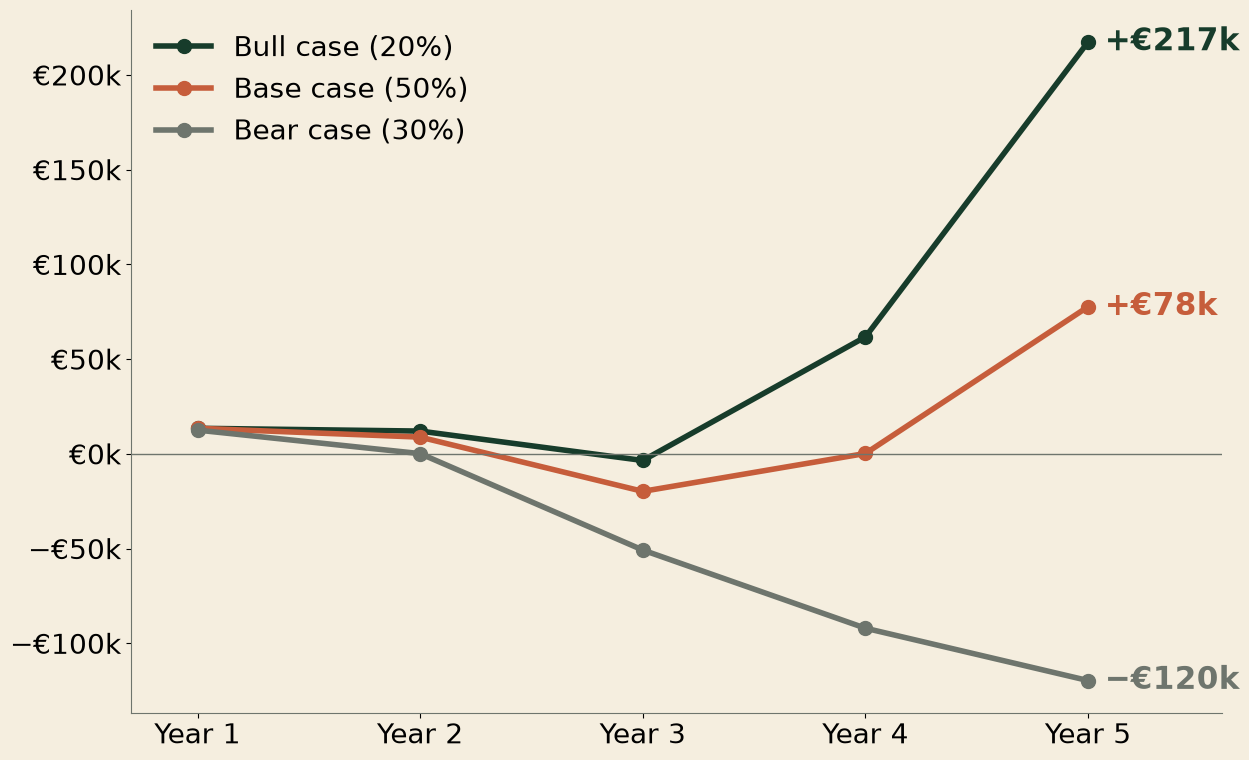

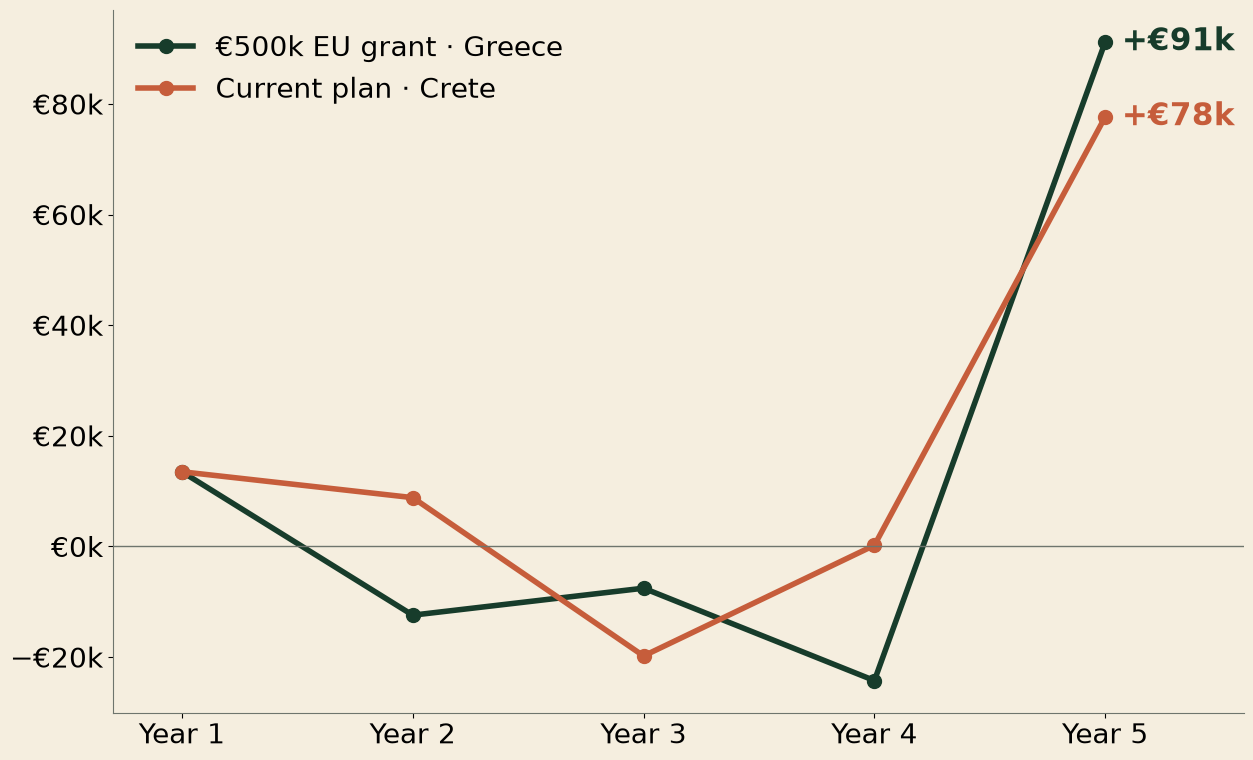

In [12]:
def slide_chart(series, fname):
    plt.rcParams.update({"font.size": 20})
    fig, ax = plt.subplots(figsize=(13, 8))
    for label, values, color in series:
        ax.plot(YEARS, values, marker="o", lw=4, ms=10, color=color, label=label)
        ax.annotate(k(values[-1], True), (5, values[-1]), textcoords="offset points",
                    xytext=(12, 0), va="center", color=color, fontweight="bold", fontsize=22)
    euro_k(ax)
    ax.set_xlim(0.7, 5.6)
    ax.legend(frameon=False, loc="upper left")
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=160)
    plt.rcParams.update({"font.size": 13})

slide_chart([("Bull case (20%)", curves["Bull"], GREEN), ("Base case (50%)", curves["Base"], ORANGE),
             ("Bear case (30%)", curves["Bear"], GREY)], "slide_risk_cases.png")
slide_chart([("€500k EU grant · Greece", compare.eu_grant_cumulative_eur.values, GREEN),
             ("Current plan · Crete", compare.current_plan_cumulative_eur.values, ORANGE)], "slide_eu_grant.png")

## 8. Numbers used in the deck

The cell below prints the sentences behind slide 10 and the backup slides, so
anyone can check them against the run above.

In [13]:
fc = first_chicago.set_index("case")
mcs = mc_summary.iloc[0]
lines = [
    f"Farmer price: €{BASE['farm_price']:.0f} per season; co-ops €{BASE['coop_member_price']:.0f} per member farm per year",
    f"Profitable without grants from Year {H['year_profitable_without_grants']}",
    f"Paying farms in Year 5: {H['paying_farms_y5']:,}",
    f"Year-5 revenue: €{H['revenue_y5_eur']:,}; Year-5 profit: €{H['profit_y5_eur']:,}",
    f"Cumulative profit by Year 5: €{H['cumulative_profit_y5_eur']:,} (lowest point €{H['lowest_cumulative_eur']:,} in Year {H['year_of_lowest_cumulative']})",
    f"First Chicago expected cumulative profit: €{expected:,.0f}",
    f"Monte Carlo: profitable in Year 5 in {mcs.p_profitable_in_year_5:.0%} of runs; all early losses recovered in {mcs.p_cumulative_positive_by_year_5:.0%}",
    f"NPV at 40%: €{npv:,.0f}",
    f"EU grant scenario: €{compare.eu_grant_cumulative_eur.iloc[-1]:,.0f} cumulative by Year 5, {int(grant_case.active_farms.iloc[-1]):,} farms",
]
pd.Series(lines).to_csv(OUT / "model" / "deck_numbers.txt", index=False, header=False)
print("\n".join(lines))

Farmer price: €25 per season; co-ops €5 per member farm per year
Profitable without grants from Year 4
Paying farms in Year 5: 4,588
Year-5 revenue: €154,088; Year-5 profit: €77,465
Cumulative profit by Year 5: €77,669 (lowest point €-19,804 in Year 3)
First Chicago expected cumulative profit: €46,415
Monte Carlo: profitable in Year 5 in 99% of runs; all early losses recovered in 68%
NPV at 40%: €16,436
EU grant scenario: €91,218 cumulative by Year 5, 22,230 farms
